
**TP 3 : Vision par ordinateur**
Module : Technologies IA, ENSA Fès, ILIA2 realisee par KAWTAR BARBARA N 5 ET AHLAME BENABBOU N6


In [5]:
!pip install -q opencv-python matplotlib scipy
!pip install -q dlib-bin
!pip install -q face_recognition --no-deps
!pip install -q face_recognition_models Click Pillow "setuptools<81"
!pip install -q ultralytics
!pip install -q --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git'

  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


**Partie 1 : Concepts de base de la vision par ordinateur**


Exercice 1 : Analyse d’une image


Étape 1 : téléverser ton image et l’afficher

In [1]:
from google.colab import files
uploaded = files.upload()
nom_image = next(iter(uploaded))
print("Image reçue :", nom_image)

KeyboardInterrupt: 

Shape : (740, 740, 3)
Type  : uint8


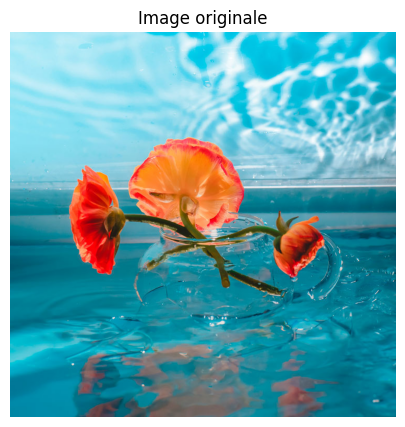

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(nom_image)
assert img is not None, "Image introuvable ou format non supporté"

print("Shape :", img.shape)    # (hauteur, largeur, 3)
print("Type  :", img.dtype)    # uint8

plt.figure(figsize=(7, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # BGR -> RGB pour l'affichage
plt.title("Image originale")
plt.axis("off")
plt.show()

Étape 2 : convertir l’image en niveaux de gris

Shape couleur : (740, 740, 3)
Shape gris    : (740, 740)


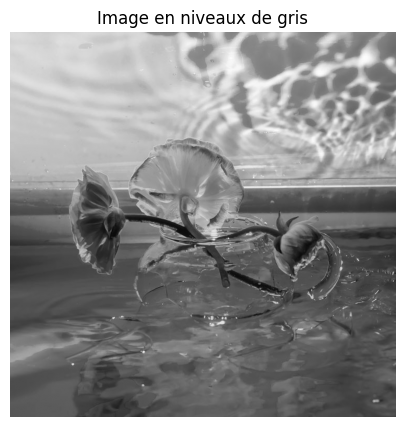

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Shape couleur :", img.shape)
print("Shape gris    :", gray.shape)

plt.figure(figsize=(7, 5))
plt.imshow(gray, cmap="gray")
plt.title("Image en niveaux de gris")
plt.axis("off")
plt.show()

Étape 3 : détection de contours avec Canny

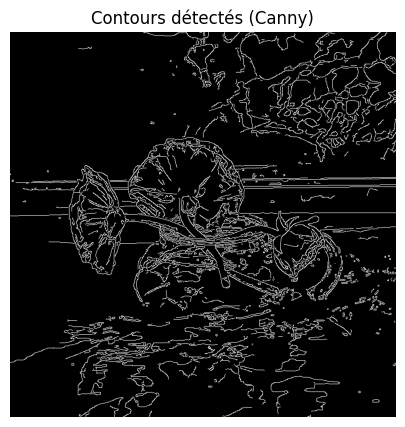

In [ ]:

edges = cv2.Canny(img, 100, 200)

plt.figure(figsize=(7, 5))
plt.imshow(edges, cmap="gray")
plt.title("Contours détectés (Canny)")
plt.axis("off")
plt.show()

### Réponses aux questions (Exercice 1)

**1. Que représente la matrice retournée par OpenCV pour l'image ?**

`cv2.imread` renvoie un tableau NumPy de forme `(hauteur, largeur, canaux)` et de type `uint8`. Chaque case correspond à un pixel et contient son intensité, de 0 (noir) à 255 (maximum), pour chaque canal. OpenCV utilise l'ordre BGR (Bleu, Vert, Rouge) et non RGB. Une image en niveaux de gris est une matrice 2D `(hauteur, largeur)`.

**2. Pourquoi convertit-on souvent l'image en niveaux de gris avant traitement ?**

- Moins de données : 1 canal au lieu de 3, donc moins de mémoire et de calcul.
- La plupart des informations utiles (contours, formes, textures) sont dans l'intensité lumineuse, pas dans la couleur.
- Les algorithmes classiques (Canny, détection de visages HOG...) fonctionnent sur un seul canal.
- Le traitement est plus robuste aux variations de couleur et d'éclairage.

**3. Flou gaussien : `blur = cv2.GaussianBlur(gray, (5, 5), 0)`. Que peut nous apporter le filtre gaussien ?**

Le filtre gaussien calcule une moyenne pondérée des pixels voisins (poids plus forts au centre). Il apporte :

- une réduction du bruit (grain du capteur, compression) ;
- un lissage qui évite que Canny détecte de faux contours sur de petites variations : avec le flou, les contours sont plus propres et moins nombreux ;
- un meilleur prétraitement pour la détection de contours.

Inconvénient : il adoucit aussi les vrais contours ; plus le noyau est grand, plus les détails fins sont perdus. `(5, 5)` est la taille du noyau (toujours impaire) et `0` laisse OpenCV calculer l'écart-type sigma.

**Partie2 : Traitement d’images et vidéos avec OpenCV**


Exercice 2 : Lecture vidéo / webcam


etape 1:fonction d’enregistrement webcam

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def record_video(filename='webcam.webm', duree=5):
    js = Javascript('''
    async function recordVideo(durationMs) {
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      video.srcObject = stream;
      video.muted = true;
      div.appendChild(video);
      document.body.appendChild(div);
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      const recorder = new MediaRecorder(stream);
      const chunks = [];
      recorder.ondataavailable = e => chunks.push(e.data);
      const done = new Promise(r => recorder.onstop = r);
      recorder.start();
      await new Promise(r => setTimeout(r, durationMs));
      recorder.stop();
      await done;
      stream.getVideoTracks()[0].stop();
      div.remove();
      const blob = new Blob(chunks, {type: 'video/webm'});
      return await new Promise(resolve => {
        const reader = new FileReader();
        reader.onloadend = () => resolve(reader.result);
        reader.readAsDataURL(blob);
      });
    }
    ''')
    display(js)
    data = eval_js('recordVideo({})'.format(int(duree * 1000)))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

enregistrer 5 secondes de webcam

In [ ]:
record_video('webcam.webm', duree=5)
!ffmpeg -y -loglevel error -i webcam.webm -r 20 webcam.mp4
print("Vidéo webcam enregistrée : webcam.mp4")

<IPython.core.display.Javascript object>

Vidéo webcam enregistrée : webcam.mp4


etape 2. Ajoutez un filtre pour convertir la vidéo en niveaux de gris en temps réel.


In [ ]:
import cv2

cap = cv2.VideoCapture('webcam.mp4')
assert cap.isOpened(), "Impossible d'ouvrir webcam.mp4"

w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 20.0

out = cv2.VideoWriter('sortie_gris.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h), isColor=False)

n = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(gray)
    n += 1

cap.release()
out.release()
print(f"{n} images traitées ({w}x{h}, {fps:.1f} FPS)")

101 images traitées (640x480, 20.0 FPS)


afficher les deux vidéos

In [ ]:
import os
from base64 import b64encode
from IPython.display import HTML

def afficher_video(chemin, largeur=400):
    h264 = chemin.replace(".mp4", "_h264.mp4")
    os.system(f"ffmpeg -y -loglevel error -i {chemin} -vcodec libx264 -pix_fmt yuv420p {h264}")
    data = b64encode(open(h264, 'rb').read()).decode()
    display(HTML(f'<video width={largeur} controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

print("Originale :")
afficher_video('webcam.mp4')
print("Niveaux de gris :")
afficher_video('sortie_gris.mp4')

Originale :


Niveaux de gris :


### Réponse à la question (Exercice 2)

**Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?**

Il suffit de remplacer `cv2.VideoCapture(0)` par `cv2.VideoCapture("video.mp4")` : le reste du code ne change pas. Les différences :

- **La vidéo a une fin.** À la dernière image, `cap.read()` renvoie `ret = False` et la boucle s'arrête d'elle-même grâce au test `if not ret: break`. La webcam est un flux continu qui ne s'arrête que lorsqu'on appuie sur `q`.
- **Le nombre d'images et la cadence sont connus à l'avance** (`CAP_PROP_FRAME_COUNT` et `CAP_PROP_FPS`), alors qu'une webcam renvoie parfois 0 FPS.
- **La vitesse de lecture n'est pas contrôlée.** Avec `waitKey(1)`, la vidéo est lue aussi vite que le processeur le permet, souvent trop vite. Pour une lecture à vitesse normale, on utilise `waitKey(int(1000/fps))`.
- **Aucune caméra n'est nécessaire**, et le traitement est reproductible : on peut comparer plusieurs algorithmes sur exactement les mêmes images.
- **Pour l'enregistrement**, la taille `(w, h)` du `VideoWriter` doit être identique à celle des images écrites, sinon le fichier de sortie est vide ou corrompu.

*Dans Colab* : la webcam de l'ordinateur n'est pas accessible directement avec `VideoCapture(0)`. On enregistre donc d'abord une vidéo avec la webcam via le navigateur, puis on la traite exactement comme une vidéo enregistrée : c'est le cas de cette question.

Partie 4 : Détection et reconnaissance faciale avec Dlib


Exercice 4 : Détection faciale


In [ ]:
!pip install -q dlib-bin

In [ ]:
from google.colab import files
uploaded = files.upload()
nom_image = next(iter(uploaded))
print("Image reçue :", nom_image)

Saving istockphoto-1398856664-612x612.jpg to istockphoto-1398856664-612x612.jpg
Image reçue : istockphoto-1398856664-612x612.jpg


détecter les visages et les entourer en vert

Visages détectés : 5


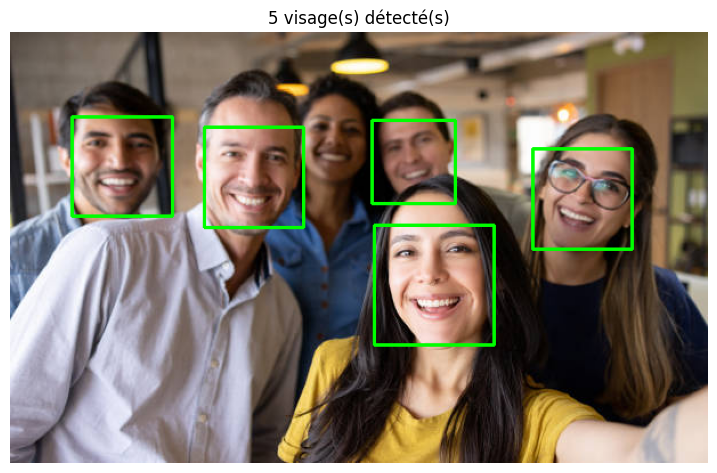

In [ ]:
import dlib
import cv2
import matplotlib.pyplot as plt

detector = dlib.get_frontal_face_detector()

img = cv2.imread(nom_image)
assert img is not None, "Image introuvable"
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = detector(gray)
print("Visages détectés :", len(faces))

for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)   # (0,255,0) = vert en BGR

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"{len(faces)} visage(s) détecté(s)")
plt.axis("off")
plt.show()

Exercice 5 : Reconnaissance faciale

In [7]:
!wget -q -O ref.jpg  https://raw.githubusercontent.com/ageitgey/face_recognition/master/tests/test_images/obama.jpg
!wget -q -O test.jpg https://raw.githubusercontent.com/ageitgey/face_recognition/master/tests/test_images/obama2.jpg

import face_recognition

enc_ref  = face_recognition.face_encodings(face_recognition.load_image_file("ref.jpg"))
enc_test = face_recognition.face_encodings(face_recognition.load_image_file("test.jpg"))

if not enc_ref or not enc_test:
    print("Aucun visage trouvé")
else:
    ok = face_recognition.compare_faces(enc_test, enc_ref[0], tolerance=0.6)
    d  = face_recognition.face_distance(enc_test, enc_ref[0])
    for i, (o, dist) in enumerate(zip(ok, d)):
        print(f"Visage {i} : même personne = {o} (distance = {dist:.3f})")

Visage 0 : même personne = True (distance = 0.346)


Réponses


1.  Plusieurs visages dans l’image test : face_encodings() renvoie un encodage par visage. Prendre [0] compare seulement le premier visage trouvé. Il faut comparer tous les visages et garder celui qui a la plus petite distance.
2.  Précision en conditions réelles : très bonne en conditions idéales (environ 99 % sur LFW), mais elle baisse avec une mauvaise lumière, des angles forts, des occlusions (masque, lunettes) ou une faible résolution.






Exercice 6 : Points caractéristiques du visage (landmarks) et EAR

Visages : 8
Visage 0 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Visage 0 : EAR moyen = 0.292
Visage 1 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Visage 1 : EAR moyen = 0.238
Visage 2 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Visage 2 : EAR moyen = 0.339
Visage 3 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Visage 3 : EAR moyen = 0.267
Visage 4 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Visage 4 : EAR moyen = 0.277
Visage 5 : parties = ['chin', 'left_eyebrow', 'right_eyebrow', 'nose_bridge', 'nose_tip', 'left_eye', 'right_eye', 'top_lip', 'bottom_lip']
Vis

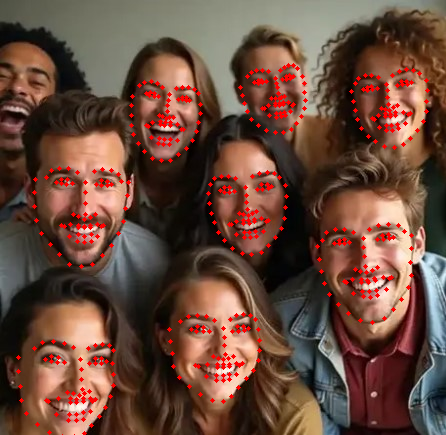

In [15]:
import cv2
import face_recognition
from scipy.spatial import distance as dist
from google.colab.patches import cv2_imshow

img = cv2.imread("people.jpg")
assert img is not None, "people.jpg introuvable"
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # face_recognition attend du RGB

landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))

def ear(eye):
    A = dist.euclidean(eye[1], eye[5])   # |p2 - p6|
    B = dist.euclidean(eye[2], eye[4])   # |p3 - p5|
    C = dist.euclidean(eye[0], eye[3])   # |p1 - p4|
    return (A + B) / (2.0 * C)

for i, lm in enumerate(landmarks_list):
    for partie, points in lm.items():
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 0, 255), -1)
    e = (ear(lm["left_eye"]) + ear(lm["right_eye"])) / 2
    print(f"Visage {i} : parties = {list(lm.keys())}")
    print(f"Visage {i} : EAR moyen = {e:.3f}")

cv2_imshow(img)

Réponses

1.   Quelles parties du visage sont retournées par face_landmarks ?
Un dictionnaire par visage, avec ces 9 parties : chin (menton / contour), left_eyebrow, right_eyebrow, nose_bridge, nose_tip, left_eye, right_eye, top_lip, bottom_lip. Elles couvrent les 68 points du modèle.
2.  EAR : comment détecter un clignement ou la somnolence ?
EAR = (‖p2−p6‖ + ‖p3−p5‖) / (2·‖p1−p4‖), c’est-à-dire la hauteur de l’œil divisée par sa largeur.


*  Œil ouvert : EAR d’environ 0,25 à 0,35.
*  Œil fermé : l’EAR tombe vers 0.
*   Clignement : l’EAR passe sous un seuil (environ 0,2 à 0,22) pendant 2 à 3 images seulement, puis remonte.
*   Somnolence : l’EAR reste sous le seuil longtemps (par exemple plus de 2 secondes). On déclenche alors une alerte.







Exercice 7 : YOLO vs Mask R-CNN

In [8]:
!pip install -q ultralytics
!pip install -q --no-build-isolation 'git+https://github.com/facebookresearch/detectron2.git'
!wget -q -O image_objects.jpg https://ultralytics.com/images/bus.jpg

  Preparing metadata (pyproject.toml) ... done


Device : cpu
YOLOv8n : objets détectés = 4


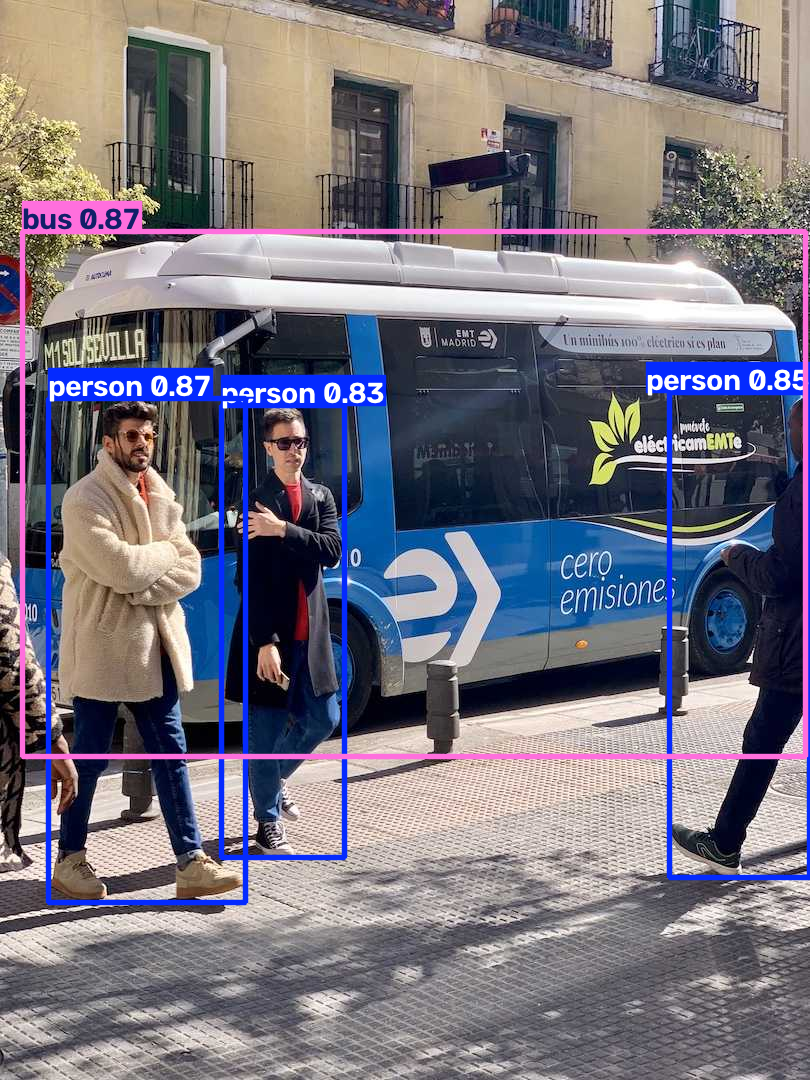

YOLOv8n-seg : masques fournis = True


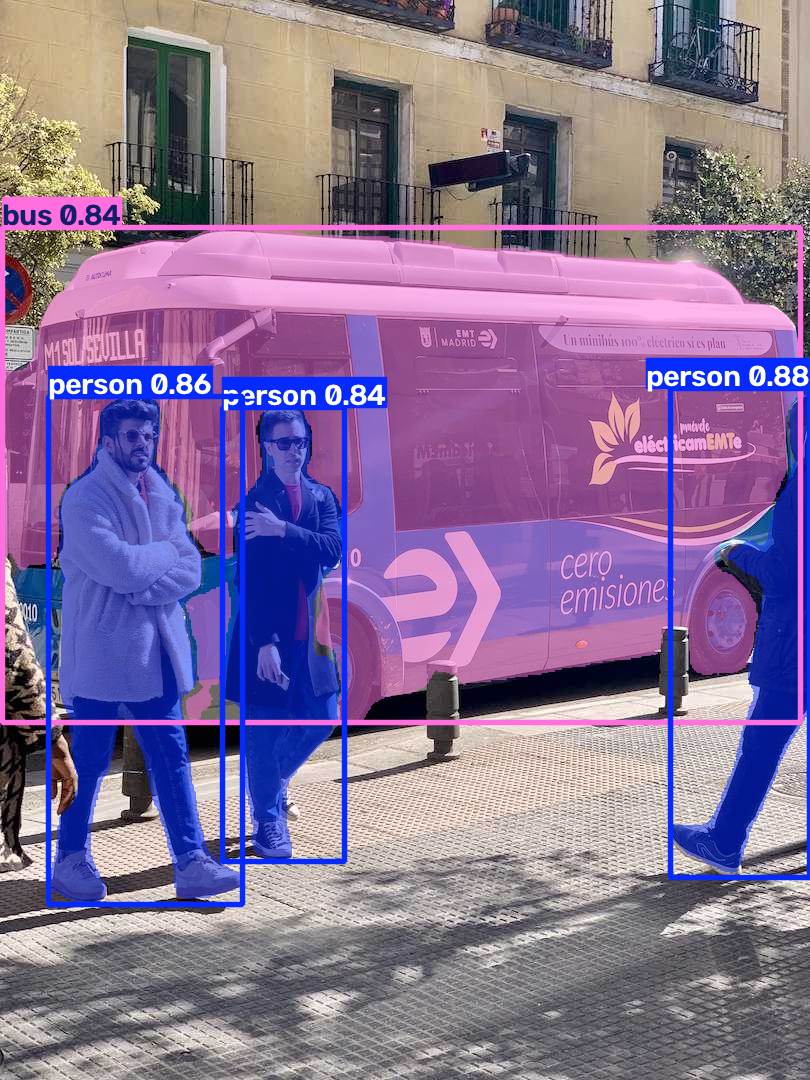

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:05<00:00, 31.8MB/s]


Mask R-CNN : objets détectés = 5


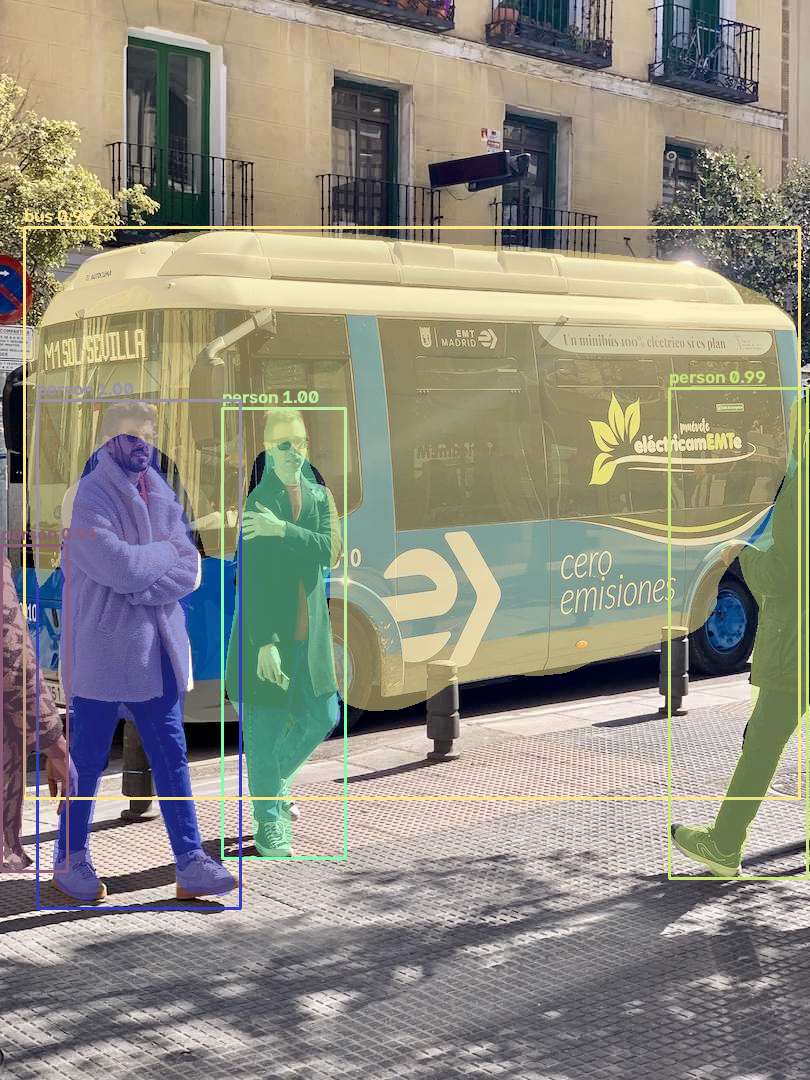


YOLOv8n     : 519 ms
YOLOv8n-seg : 623 ms
Mask R-CNN  : 11739 ms
Mask R-CNN est ~22.6x plus lent que YOLOv8n


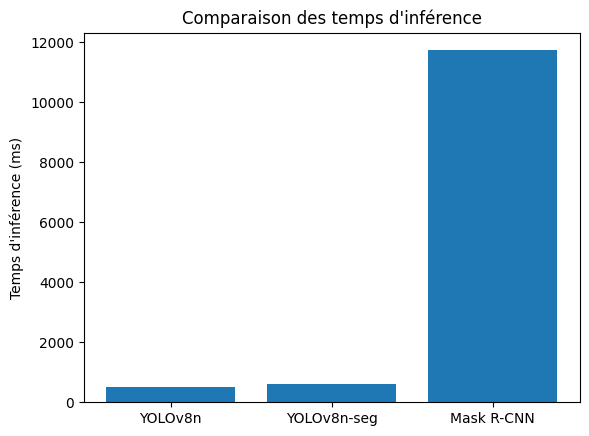

In [16]:
import time, cv2, torch
import matplotlib.pyplot as plt
from ultralytics import YOLO
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import to_tensor
from google.colab.patches import cv2_imshow

path = "image_objects.jpg"
img_bgr = cv2.imread(path)
assert img_bgr is not None, "image_objects.jpg introuvable ou vide"
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

# ---------- a) YOLOv8n (détection) ----------
yolo = YOLO("yolov8n.pt")
yolo(path, verbose=False)                       # appel de chauffe
t0 = time.time()
res = yolo(path, conf=0.5, verbose=False)
t_yolo = time.time() - t0
print("YOLOv8n : objets détectés =", len(res[0].boxes))
cv2_imshow(res[0].plot())

# ---------- b) YOLOv8n-seg (masques) ----------
yolo_seg = YOLO("yolov8n-seg.pt")
yolo_seg(path, verbose=False)
t0 = time.time()
res_seg = yolo_seg(path, conf=0.5, verbose=False)
t_seg = time.time() - t0
print("YOLOv8n-seg : masques fournis =", res_seg[0].masks is not None)
cv2_imshow(res_seg[0].plot())

# ---------- c) Mask R-CNN (torchvision) ----------
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mask_model = maskrcnn_resnet50_fpn(weights=weights).to(device).eval()
categories = weights.meta["categories"]
x = to_tensor(img_rgb).to(device)

with torch.no_grad():
    mask_model([x])                             # appel de chauffe
    sync()
    t0 = time.time()
    out = mask_model([x])[0]
    sync()
    t_mask = time.time() - t0

# visualisation : masques colorés + étiquettes (score > 0.5)
vis = img_bgr.copy()
n = 0
for box, label, score, mask in zip(out["boxes"], out["labels"], out["scores"], out["masks"]):
    if score < 0.5:
        continue
    n += 1
    m = (mask[0] > 0.5).cpu().numpy()
    couleur = tuple(int(c) for c in torch.randint(50, 255, (3,)))
    vis[m] = (0.5 * vis[m] + 0.5 * torch.tensor(couleur).numpy()).astype("uint8")
    x1, y1, x2, y2 = [int(v) for v in box.tolist()]
    cv2.rectangle(vis, (x1, y1), (x2, y2), couleur, 2)
    cv2.putText(vis, f"{categories[label]} {score:.2f}", (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, couleur, 2)
print("Mask R-CNN : objets détectés =", n)
cv2_imshow(vis)

# ---------- Comparaison ----------
print(f"\nYOLOv8n     : {t_yolo*1000:.0f} ms")
print(f"YOLOv8n-seg : {t_seg*1000:.0f} ms")
print(f"Mask R-CNN  : {t_mask*1000:.0f} ms")
print(f"Mask R-CNN est ~{t_mask/t_yolo:.1f}x plus lent que YOLOv8n")

plt.bar(["YOLOv8n", "YOLOv8n-seg", "Mask R-CNN"], [t_yolo*1000, t_seg*1000, t_mask*1000])
plt.ylabel("Temps d'inférence (ms)")
plt.title("Comparaison des temps d'inférence")
plt.show()

Réponses

1.  Temps d’inférence : YOLOv8n est beaucoup plus rapide que Mask R-CNN, souvent de 5 à 10 fois ou plus. Les valeurs exactes sont affichées par le code et dépendent du GPU.
2.  Masques de segmentation : yolov8n.pt donne seulement des boîtes. yolov8n-seg.pt donne aussi des masques (results[0].masks), un peu moins précis sur les contours que Mask R-CNN.
3. Quand choisir quoi : YOLO pour le temps réel (vidéo, webcam, comptage, embarqué). Mask R-CNN quand la précision des contours compte plus que la vitesse (analyse d’images fixes, médical).








 Mini-projet


In [11]:
!pip install -q dlib-bin opencv-python

In [12]:
from google.colab import files
up = files.upload()
nom = list(up.keys())[0]
import os
os.rename(nom, "people.jpg")

Saving people.jpg to people (1).jpg


floutage

Visages floutés : 7
Avant :


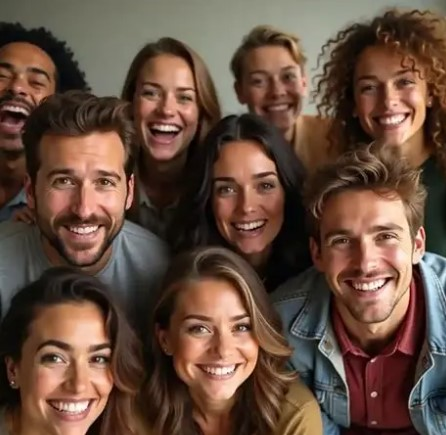

Après :


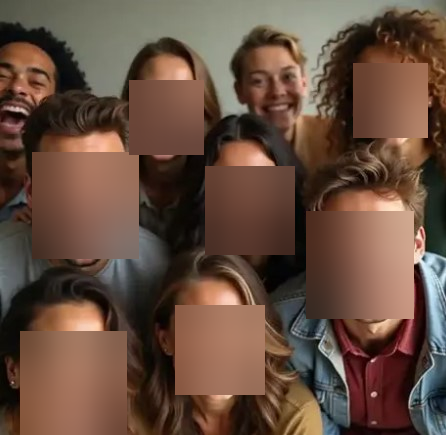

True

In [13]:
import cv2, dlib
from google.colab.patches import cv2_imshow

detector = dlib.get_frontal_face_detector()

def flouter_visages(img, noyau=99, sigma=30):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = detector(gray, 1)
    for f in faces:
        x1, y1 = max(f.left(), 0), max(f.top(), 0)
        x2, y2 = min(f.right(), img.shape[1]), min(f.bottom(), img.shape[0])
        zone = img[y1:y2, x1:x2]
        if zone.size:
            img[y1:y2, x1:x2] = cv2.GaussianBlur(zone, (noyau, noyau), sigma)
    return img, len(faces)

original = cv2.imread("people.jpg")
assert original is not None, "people.jpg introuvable"

resultat, n = flouter_visages(original.copy())
print("Visages floutés :", n)

print("Avant :");  cv2_imshow(original)
print("Après :");  cv2_imshow(resultat)
cv2.imwrite("visages_floutes.jpg", resultat)

# Floutage automatique des visages

## Objectif
Anonymiser automatiquement les visages présents dans une image ou une vidéo
(conformité vie privée) : détection des visages puis application d'un flou
gaussien (`cv2.GaussianBlur`) sur chaque zone détectée.

## Installation
pip install dlib-bin opencv-python numpy
(Google Colab : !pip install dlib-bin opencv-python)

## Utilisation
1. Placer une image `people.jpg` (avec un ou plusieurs visages de face) dans le dossier.
2. Exécuter le notebook ou le script.
3. Le résultat est enregistré dans `visages_floutes.jpg`.
Version vidéo : importer un fichier vidéo, le résultat est `video_floutee.mp4`.

## Fonctionnement
- Détection : `dlib.get_frontal_face_detector()` (HOG + SVM) sur l'image en niveaux de gris.
- Floutage : `cv2.GaussianBlur(zone, (99, 99), 30)` appliqué à chaque rectangle détecté.

## Limites
- Le détecteur est fiable pour les visages de face ; les profils, les petits
  visages et les visages partiellement cachés peuvent être manqués
  (visage non flouté = risque pour la vie privée).